# Bonus — Model Performance Estimation
## From Holdout to Repeated Nested Cross-Validation

**Advanced self-learning material**

> **This is optional, advanced material.** Confidence intervals, bootstrap and some of the statistical arguments below go beyond the core bootcamp curriculum. You are **not expected to master every mathematical detail**. First focus on why each validation strategy exists and how to implement it; the deeper statistical discussions are for curious learners who want to go further.

**Main question:** *After tuning a model, how reliably can we estimate its performance on unseen data?*

**Learning goals**
- Distinguish model selection from independent performance estimation.
- Implement holdout, K-fold, nested CV and repeated nested CV.
- Introduce confidence intervals (CIs) and bootstrap **from scratch**: neither was covered in the statistics week.
- Recognize why dependence between folds compromises naive confidence intervals.
- Distinguish uncertainty for a **fixed fitted model** from uncertainty for an **entire training-and-tuning procedure**.


## 0. A common dataset

We reuse the built-in **Diabetes** regression dataset and a Random Forest, so the focus stays on evaluation rather than a new algorithm. The search space is deliberately small to keep the notebook practical.

We use **MAE** (mean absolute error): lower is better. For `cross_val_score` and `GridSearchCV`, scikit-learn uses `neg_mean_absolute_error` because its scorer interface assumes higher is better.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import t
from sklearn.datasets import load_diabetes
from sklearn.model_selection import (train_test_split, KFold, RepeatedKFold,
                                     GridSearchCV, cross_validate)
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error

SEED = 42
X, y = load_diabetes(return_X_y=True, as_frame=True)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED
)

# This is the learning procedure A: pipeline + hyperparameter search + refit.
def make_search():
    pipeline = Pipeline([
        ("model", RandomForestRegressor(random_state=SEED, n_jobs=1))
    ])
    return GridSearchCV(
        estimator=pipeline,
        param_grid={"model__max_depth": [3, 7], "model__min_samples_leaf": [2, 6]},
        scoring="neg_mean_absolute_error",
        cv=KFold(n_splits=3, shuffle=True, random_state=SEED),
        refit=True,
        n_jobs=-1,
    )

print(f"Training rows: {len(X_train)} | Held-out test rows: {len(X_test)}")

## 1. What is generalization error?

A learning **procedure** includes the model, the search space, the cross-validation strategy and the rule used to select hyperparameters. We write it as $A$.

$$R(A)=\mathbb{E}_{D,Z}\left[L(A(D),Z)\right]$$

| Symbol | Meaning | Python connection |
|---|---|---|
| $A$ | Entire learning-and-selection procedure | `make_search()` creates `GridSearchCV` around a `Pipeline`; inner CV is `KFold(n_splits=3)` |
| $D$ | A possible training dataset, with targets | In one run: `(X_train, y_train)`; mathematically it can vary |
| $A(D)$ | Fitted result of training and selection | `search.fit(X_train, y_train)`; `search.best_estimator_` |
| $Z$ | A new observation **including its target** | One `(X_new, y_new)` pair |
| $L$ | Loss on one observation | `abs(y_new - prediction)` |
| $\mathbb{E}_{D,Z}$ | Theoretical average over possible training datasets **and** new observations | Not simply `scores.mean()`; it cannot be observed exactly |

**Important distinction:** $R(A)$ averages over the randomness of *future training datasets* as well as new examples. The generalization error of **one particular already-fitted model** conditions on its training dataset and is a different target. Our finite-sample CV estimates approximate procedure performance at their training-fold sizes, not necessarily the performance of the final model trained on every available row.

**Check for understanding:** Why can the best hyperparameters differ between two outer folds even though we use the same `GridSearchCV` settings?

## 2. Confidence intervals: a short introduction

### From population to observed data

We imagine an unknown population distribution $P$ that generates independent observations $(X,y)$. The observed dataset $D$ is **one random sample from $P$**. A train/test split then produces two disjoint subsets of this observed dataset:

$$P\;\xrightarrow{\\text{sampling}}\;D\;\xrightarrow{\\text{splitting}}\;\bigl(D_{\\text{train}},D_{\\text{test}}\bigr)$$

In Python, $D$ corresponds to `(X, y)`, while $D_{\\text{train}}` corresponds to `(X_train, y_train)`. These are **paired features and targets**, not just the feature matrix. We write arrows rather than $D\\subset P$, because $P$ is a probability distribution, not necessarily a finite set.

### What does a confidence interval mean?

A point estimate such as **MAE = 45** does not tell us how precise that number is. How much might it change if we evaluated the model on a different set of new observations ($Z$), or if we trained it on a different dataset ($D$)? Those are two different sources of uncertainty. A **confidence interval (CI)** is produced by a procedure designed to cover a fixed population quantity at a stated long-run rate, such as 95%, under its assumptions. It is **not** a 95% probability that the fixed unknown parameter lies inside this particular realized interval.

For approximately independent, identically distributed measurements $x_1,\dots,x_n$ whose mean admits a suitable t approximation, the familiar formula is:

$$\bar{x}\ \pm\ t_{1-\alpha/2,n-1}\frac{\hat\sigma_x}{\sqrt{n}}$$

Here $\bar{x}$ is the sample mean; $\hat\sigma_x$ is the **sample standard deviation** (estimated from the observations with `ddof=1`); $n$ is the number of independent observations; and $t_{1-\alpha/2,n-1}$ is a critical quantile of Student's t distribution. We use $\hat\sigma_x$ rather than $\sigma_x$ to emphasize that the population standard deviation is unknown and must be estimated.

- **CDF**: `t.cdf(value, df)` gives cumulative probability up to a value.
- **PPF**: `t.ppf(probability, df)` returns the value with that cumulative probability.

The key question throughout this notebook: **What exactly counts as an independent observation?**

In [ ]:
# Toy example: independent measurements (NOT cross-validation fold scores).
toy_measurements = np.array([40., 44., 47., 43., 46., 42., 45., 41.])
n = len(toy_measurements)
mean = toy_measurements.mean()
sd = toy_measurements.std(ddof=1)
critical = t.ppf(0.975, df=n - 1)
margin = critical * sd / np.sqrt(n)
print(f"Toy 95% t interval: [{mean-margin:.2f}, {mean+margin:.2f}]")
print(f"CDF at the critical value: {t.cdf(critical, df=n-1):.3f}")

### Bootstrap: a second way to quantify uncertainty

Bootstrap generates many **resamples with replacement** from the observed data and recalculates a statistic on each. A simple **percentile interval** takes the 2.5th and 97.5th percentiles of the bootstrap estimates. This is an introduction, **not** a guarantee that any bootstrap interval is valid for any dependent data or statistic.

For a fixed fitted model, resampling its individual **test losses** can approximate uncertainty due to which independent test observations were sampled. It **does not** capture uncertainty due to retraining or hyperparameter selection.

In [ ]:
def bootstrap_mean_interval(values, n_resamples=1000, confidence=0.95, seed=SEED):
    """Percentile bootstrap of the mean; assumes exchangeable/independent units."""
    values = np.asarray(values, dtype=float)
    rng = np.random.default_rng(seed)
    indices = rng.integers(0, len(values), size=(n_resamples, len(values)))
    bootstrap_means = values[indices].mean(axis=1)
    alpha = 1 - confidence
    limits = np.quantile(bootstrap_means, [alpha / 2, 1 - alpha / 2])
    return limits, bootstrap_means

interval, toy_boot = bootstrap_mean_interval(toy_measurements)
print(f"Toy percentile bootstrap interval: [{interval[0]:.2f}, {interval[1]:.2f}]")
plt.hist(toy_boot, bins=25)
plt.axvline(interval[0], linestyle="--")
plt.axvline(interval[1], linestyle="--")
plt.title("Bootstrap distribution of the sample mean (toy data)")
plt.xlabel("Bootstrap mean")
plt.show()

## 3. Holdout: one independent final evaluation

**What changes?** The random split changes both the training sample $D$ and the evaluation observations $Z$ (the learning procedure $A$ stays fixed):

$$R(A)=\mathbb{E}_{\color{red}{D},\color{red}{Z}}\left[L\left(A(\color{red}{D}),\color{red}{Z}\right)\right]$$

We tune **only on the training portion** and evaluate the selected fitted model on the untouched test portion. The diagram shows the *outer* separation; inner validation occurs inside `GridSearchCV`.

**The split depends on the random seed.** With `train_test_split(..., random_state=SEED)`, changing `SEED` changes which rows belong to `X_train` and `X_test` (and their targets). In the notation above, our observed training dataset $D$ changes, and so does the set of evaluation observations $Z$. If we collect a different original dataset, both may change as well. A fixed seed makes this experiment reproducible; it does not make its result universal.

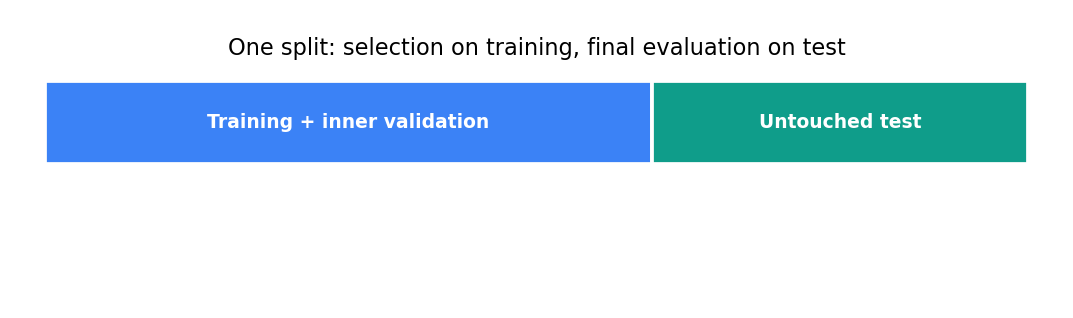

In [ ]:
search = make_search()
search.fit(X_train, y_train)
predictions = search.predict(X_test)
losses_test = np.abs(y_test.to_numpy() - predictions)
holdout_mae = losses_test.mean()
print("Selected hyperparameters:", search.best_params_)
print(f"Best inner CV MAE (selection score): {-search.best_score_:.2f}")
print(f"Untouched holdout MAE: {holdout_mae:.2f}")

# The bootstrap unit is a TEST OBSERVATION, not a model or a CV fold.
holdout_ci, _ = bootstrap_mean_interval(losses_test)
print(f"Illustrative 95% bootstrap CI for this fixed model's mean test loss: {holdout_ci}")

**Statistical considerations.** This test-loss bootstrap conditions on the selected fitted model. It is reasonable as an illustration when test observations are independent and representative, but it does **not** estimate the training-and-selection variability in $R(A)$. With only one train/test split we also cannot observe how the procedure changes across possible training samples.

**Check for understanding:** Why would using the test set to choose `max_depth` invalidate its role as an untouched final evaluation?

## 4. K-Fold CV: reducing dependence on one split

**What changes?** The original observed dataset is fixed, but the fold-specific training subset $D$ and validation observations $Z$ rotate through its rows:

$$R(A)=\mathbb{E}_{\color{red}{D},\color{red}{Z}}\left[L\left(A(\color{red}{D}),\color{red}{Z}\right)\right]$$

Here $K$ is the **number of folds**. With $K=4$, each outer model trains on three blocks and is evaluated on the fourth.

Here we choose **K = 4** (four folds) in advance: in each fold, the estimator is fitted on three blocks and scored on the remaining block. Choosing a different $K$ changes the training/validation sizes and may also change which hyperparameters are selected. To evaluate **the full tuning procedure**, the estimator passed to outer CV is `make_search()`, not just a Random Forest with preselected hyperparameters.

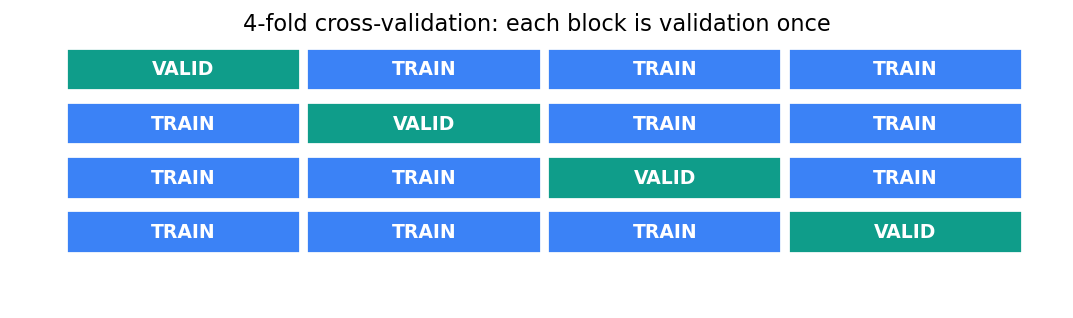

In [ ]:
outer_cv = KFold(n_splits=4, shuffle=True, random_state=SEED)
# GridSearchCV is refitted within each of the four evaluation folds.
kfold_result = cross_validate(
    make_search(), X_train, y_train,
    cv=outer_cv, scoring="neg_mean_absolute_error", n_jobs=1,
    return_estimator=False,
)
kfold_mae = -kfold_result["test_score"]
print("Outer-fold MAEs:", np.round(kfold_mae, 2))
print(f"Mean: {kfold_mae.mean():.2f} | Fold SD: {kfold_mae.std(ddof=1):.2f}")

**Statistical considerations.** The four outer-fold scores are **not four independent experiments**: their training datasets overlap heavily, and all are drawn from the same original dataset. Applying $\bar{x}\pm t\,\hat\sigma_x/\sqrt{4}$ to these scores as though they were i.i.d. gives an unjustified CI.

An illustrative alternative is to collect each observation's **out-of-fold absolute loss**, then bootstrap observations. That estimates variation in the empirical mean of those losses **while treating the fitted fold models as fixed**; it does not capture the full dependence or uncertainty of the training-and-tuning procedure. We label this as a *conditional, exploratory interval*, not a validated CI for $R(A)$.

In [ ]:
def out_of_fold_losses(estimator_factory, X_data, y_data, cv):
    """Fit the full procedure in each outer fold; return one loss per row."""
    losses = np.full(len(y_data), np.nan)
    for train_idx, valid_idx in cv.split(X_data, y_data):
        fitted = estimator_factory()
        fitted.fit(X_data.iloc[train_idx], y_data.iloc[train_idx])
        pred = fitted.predict(X_data.iloc[valid_idx])
        losses[valid_idx] = np.abs(y_data.iloc[valid_idx].to_numpy() - pred)
    assert np.isfinite(losses).all()
    return losses

kfold_losses = out_of_fold_losses(
    make_search, X_train, y_train,
    KFold(n_splits=4, shuffle=True, random_state=SEED),
)
kfold_boot_ci, _ = bootstrap_mean_interval(kfold_losses)
print(f"OOF mean MAE: {kfold_losses.mean():.2f}")
print("Exploratory bootstrap interval of OOF losses:", np.round(kfold_boot_ci, 2))

### Optional bridge: Repeated K-Fold

`RepeatedKFold` keeps the **original dataset $D$ fixed**, but repeatedly creates different training and validation subsets from those same observations. In code, the rows supplied as `X_train, y_train` stay the same; the fold-specific training and test indices change with each repetition. (These fold-specific test subsets are not the untouched final `X_test` from holdout.) More scores can help reveal sensitivity to the split, but they do **not** become independent samples just because there are more of them. We will use the same idea with nested CV later.

**Check for understanding:** If two training folds share most of their observations, why might their errors be correlated?

**Going deeper — could we force independence?** One possibility is to partition the dataset into **disjoint blocks**, then train and test a separate model entirely within each block. Under i.i.d. sampling and no shared fitted preprocessing, this can make block-level evaluations independent. However, every model then trains on far fewer rows, changing the learning problem and often increasing score variability. For example, with 400 rows, ordinary 4-fold CV trains on 300 rows per fold; four disjoint blocks with a 75/25 holdout train on only 75 rows each. **Independence alone does not guarantee that we estimate the performance of the procedure we plan to deploy.**

**Check for understanding:** Why would the block-based estimates not describe a model trained on 300 or 400 rows?

## 5. Nested CV: separate tuning from evaluation

**What changes?** The outer folds change $D$ and $Z$. Most importantly, $A$ now explicitly includes **inner hyperparameter search and refitting**, rather than a model with fixed hyperparameters:

$$R(\color{red}{A})=\mathbb{E}_{D,Z}\left[L\left(\color{red}{A}(D),Z\right)\right]$$

The red $A$ emphasizes the *procedure being evaluated*; it is defined before the experiment and does not change between outer folds.

**Inner CV** chooses hyperparameters. **Outer CV** evaluates the complete choice-and-refit procedure on data never used by its inner search. Each outer training fold performs a fresh `GridSearchCV`.

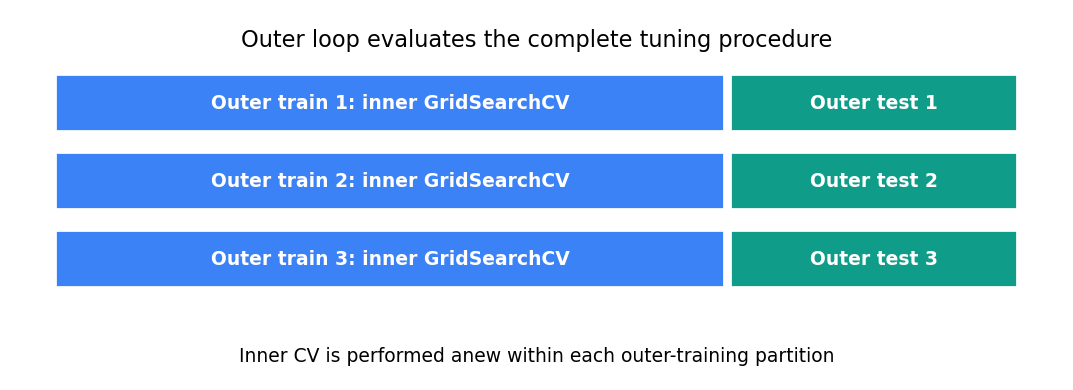

In [ ]:
# This is nested CV: outer cross_validate wraps inner GridSearchCV.
nested_result = cross_validate(
    make_search(), X_train, y_train,
    cv=KFold(n_splits=4, shuffle=True, random_state=SEED),
    scoring="neg_mean_absolute_error", return_estimator=True, n_jobs=1,
)
nested_mae = -nested_result["test_score"]
selected = [fit.best_params_ for fit in nested_result["estimator"]]
print("Outer MAEs:", np.round(nested_mae, 2))
print("Inner-selected parameters per outer fold:")
for i, params in enumerate(selected, start=1):
    print(f"  Fold {i}: {params}")

**Important observation:** the K-Fold code above was **already nested** because it passed `GridSearchCV` as the estimator to an outer CV. We made that explicit here instead of pretending that K-Fold and nested CV are mutually exclusive techniques. The difference is **what is fitted inside each evaluation fold**: a fixed model vs a tuning procedure.

**Statistical considerations.** Nested CV helps avoid the optimistic bias of reporting the best *inner* CV score as an independent performance estimate. But outer scores still depend on overlapping training samples. A naive t interval over the four outer scores is not automatically valid. The OOF bootstrap below is illustrative, with the same limitations as in the previous section.

In [ ]:
# Reuse the outer predictions: one independent-of-selection evaluation per row.
# Same splits as above; this recalculates the fits for teaching transparency.
nested_losses = out_of_fold_losses(
    make_search, X_train, y_train,
    KFold(n_splits=4, shuffle=True, random_state=SEED),
)
nested_ci, _ = bootstrap_mean_interval(nested_losses)
print(f"Nested OOF mean MAE: {nested_losses.mean():.2f}")
print("Exploratory bootstrap interval:", np.round(nested_ci, 2))

**Check for understanding:** Why does a nested outer test fold remain untouched by the inner hyperparameter search? Why can two outer folds select different hyperparameters?

## 6. Repeated Nested CV: examine stability across partitions

**What changes?** We repeatedly redraw the outer splits of the **same observed dataset**. Each split gives a different training subset $D$ and evaluation subset $Z$; the full tuning procedure $A$ remains fixed:

$$R(A)=\mathbb{E}_{\color{red}{D},\color{red}{Z}}\left[L\left(A(\color{red}{D}),\color{red}{Z}\right)\right]$$

Repeating partitions does **not** generate new independent datasets from the population.

We repeat the entire outer CV with different shuffled partitions. The **inner** search remains inside each outer-training fold. The same original observations appear again in each repeat, so the resulting scores are strongly dependent.

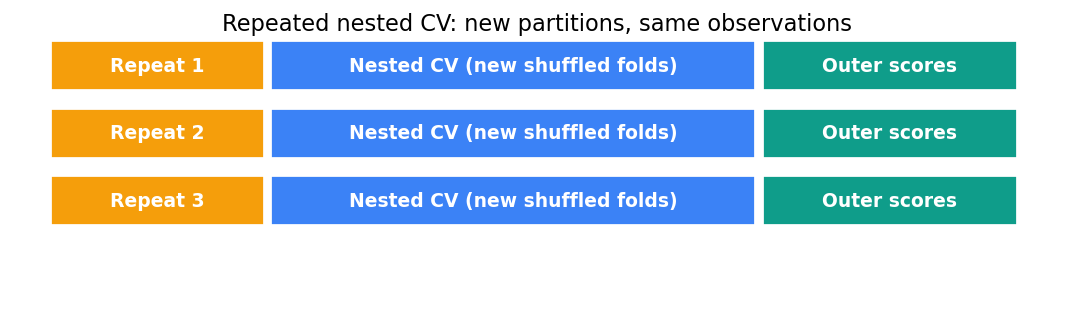

In [ ]:
N_REPEATS = 3
N_OUTER = 4
repeated_cv = RepeatedKFold(n_splits=N_OUTER, n_repeats=N_REPEATS, random_state=SEED)
rows = []
# Each row accumulates multiple out-of-fold losses, one per repetition.
loss_matrix = np.full((N_REPEATS, len(y_train)), np.nan)
for fold_id, (train_idx, valid_idx) in enumerate(repeated_cv.split(X_train, y_train)):
    repeat = fold_id // N_OUTER
    fold = fold_id % N_OUTER
    fitted = make_search()
    fitted.fit(X_train.iloc[train_idx], y_train.iloc[train_idx])
    pred = fitted.predict(X_train.iloc[valid_idx])
    losses = np.abs(y_train.iloc[valid_idx].to_numpy() - pred)
    loss_matrix[repeat, valid_idx] = losses
    rows.append({"repeat": repeat + 1, "outer_fold": fold + 1,
                 "mae": losses.mean(), "max_depth": fitted.best_params_["model__max_depth"]})

results = pd.DataFrame(rows)
assert np.isfinite(loss_matrix).all()
print(results.to_string(index=False))
print("\nMean MAE per repeat:\n", results.groupby("repeat")["mae"].mean())

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for repeat, group in results.groupby("repeat"):
    axes[0].plot(group["outer_fold"], group["mae"], marker="o", label=f"Repeat {repeat}")
axes[0].set(xlabel="Outer fold", ylabel="MAE", title="Variation across splits")
axes[0].legend()
results["max_depth"].value_counts().sort_index().plot.bar(ax=axes[1])
axes[1].set(xlabel="Selected max_depth", ylabel="Number of outer folds", title="Selection stability")
plt.tight_layout()
plt.show()

# Average repeated OOF losses by ORIGINAL OBSERVATION before resampling rows.
per_observation_loss = loss_matrix.mean(axis=0)
repeated_ci, _ = bootstrap_mean_interval(per_observation_loss)
print("Exploratory interval (row-level resampling; not a CI for R(A)):",
      np.round(repeated_ci, 2))

**Statistical considerations.** Twelve outer scores are **not twelve independent datasets**. Even averaging losses across repetitions for each original observation and bootstrapping those rows does **not** account for the dependence created by refitting on overlapping training data. The displayed interval is exploratory, **not a formal 95% CI for $R(A)$**.

**Check for understanding:** Why would increasing the number of repetitions from 3 to 30 not give us 10 times as many independent training datasets?

## 7. Compare the strategies — without overinterpreting the intervals

We can compare point estimates and the *descriptive* spread of results, but the intervals shown so far answer different, limited questions. In particular, an interval on test losses for a fixed model and a resampling interval on OOF losses are **not interchangeable**.

In [ ]:
comparison = pd.DataFrame([
    {"Strategy": "Holdout (fixed fitted model)", "MAE": holdout_mae,
     "Interval lower": holdout_ci[0], "Interval upper": holdout_ci[1]},
    {"Strategy": "K-Fold / nested tuning procedure", "MAE": kfold_losses.mean(),
     "Interval lower": kfold_boot_ci[0], "Interval upper": kfold_boot_ci[1]},
    {"Strategy": "Repeated nested (row-averaged OOF)", "MAE": per_observation_loss.mean(),
     "Interval lower": repeated_ci[0], "Interval upper": repeated_ci[1]},
])
print(comparison.round(2).to_string(index=False))
print("All intervals are conditional/exploratory; do NOT compare them as validated CIs for R(A).")

## 8. Going deeper — bootstrap the *entire* learning procedure

A more ambitious bootstrap resamples **training rows** and runs the full `GridSearchCV` again. This can reveal how hyperparameter choices and fitted-model performance vary across plausible training samples.

For this short demonstration, we evaluate every bootstrap-fitted model on the **same untouched test set**. The resulting distribution is **not automatically a confidence interval for** $R(A)$: the test set is reused, its sampling uncertainty is not independently resampled, and the bootstrap training distribution is only an approximation to the population. The purpose is to *see training-and-selection variability*, not to claim coverage.

Set `N_BOOTSTRAP_FITS` higher only if you have time: each bootstrap replicate performs a complete hyperparameter search.

In [ ]:
N_BOOTSTRAP_FITS = 12  # Educational illustration; far too few for a precise percentile CI.
rng = np.random.default_rng(SEED)
bootstrap_test_mae = []
bootstrap_depth = []
for b in range(N_BOOTSTRAP_FITS):
    sampled_rows = rng.integers(0, len(X_train), size=len(X_train))
    fitted = make_search()
    fitted.fit(X_train.iloc[sampled_rows], y_train.iloc[sampled_rows])
    test_pred = fitted.predict(X_test)
    bootstrap_test_mae.append(mean_absolute_error(y_test, test_pred))
    bootstrap_depth.append(fitted.best_params_["model__max_depth"])

print("Test MAEs across bootstrap-trained models:", np.round(bootstrap_test_mae, 2))
print("Selected depths:", bootstrap_depth)
plt.hist(bootstrap_test_mae, bins=min(8, N_BOOTSTRAP_FITS))
plt.xlabel("MAE on the same held-out test set")
plt.ylabel("Number of bootstrap-fitted models")
plt.title("Training-and-selection variability (illustration only)")
plt.show()

## 9. Which strategy should we choose?

**If the goal is the performance of one final, already-fitted model:** keep an independent test set untouched throughout tuning and model selection. Evaluate the final model once, and (for i.i.d. test observations) use a **bootstrap of individual test losses** to estimate test-sampling uncertainty conditional on that fitted model. This does **not** capture uncertainty from retraining the model on a different dataset.

**If the goal is the expected performance of a full model-selection procedure $A$:** prefer **nested cross-validation**: inner CV tunes; outer CV evaluates the complete tuning-and-refit procedure. **Repeated nested CV** additionally reveals sensitivity to how the observed dataset is partitioned. Its outer scores are dependent, so their naive t interval is not automatically a valid 95% CI for $R(A)$.

**If a defensible confidence interval for $R(A)$ is essential:** first specify the exact target (including training-set size and data-generating assumptions). Use a validated inference procedure appropriate to that target, or collect genuinely independent evaluation data / independently sampled training datasets where feasible. A carefully designed full-procedure bootstrap may be explored, but simply taking percentiles of repeated-CV scores or bootstrap-refit scores **does not guarantee 95% coverage**.

### What should we remember?

- **Holdout:** evaluates a fixed fitted model on untouched data; bootstrap test losses addresses conditional evaluation uncertainty.
- **K-Fold:** reduces reliance on a single split, but overlapping training sets make fold scores dependent.
- **Nested CV:** avoids evaluating tuning choices on the same folds used to select them.
- **Repeated nested CV:** examines partition sensitivity, not independent replications of the population sampling process.
- **Bootstrap:** the unit being resampled and the estimator being recomputed determine what uncertainty is represented.

**Final reflection:** What would need to change if you wanted an interval for the expected performance of the *entire* training-and-tuning procedure, rather than for one already-fitted model?